# Spin–boson model: reorganization of equilibrium information

This notebook covers Sec. V of the paper and produces Figs. 3 and 4
(`spin_boson_equilibrium`, `spin_boson_finite_error`).

The fermionic models are exactly solvable; the spin–boson model is not. It is the test of
whether the bound can be *evaluated* when the mean-force Gibbs (MFG) state has to be computed
numerically, and of what it says over the whole range from weak to ultrastrong coupling. Both
the equilibrium states and the real-time dynamics come from TEMPO (time-evolving matrix product
operators), in imaginary and real time respectively, through the OQuPy implementation.

As in the other two notebooks, nothing here is recomputed from the Hamiltonian: the stored
output of the TEMPO pipeline is read, a few quantities are re-derived from more elementary ones
as a check, and the figures are rebuilt. Section 6 says how to rerun the pipeline.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

import planckian as pk
import plotstyle as ps
from planckian import read_csv, select, column, sort_by
from plotstyle import (EPS_COLOR, BLUES, BLUE_MAIN, RED, GREY_REF, LW_REF,
                       figure, grid, title, shared_legend, eps_label)

DATA = Path('data/spin_boson')
FIGS = Path('figures'); FIGS.mkdir(exist_ok=True)
ps.setup()

LWD, LWD_SB, MS_D, MS_SB = 1.1, 1.0, 2.8, 2.3


def save(fig, name):
    fig.savefig(FIGS / f'{name}.pdf')
    return fig

## 1. Model and conventions

A spin coupled through $\sigma_z$ to a bath of harmonic oscillators [Eq. (35)],

$$H_S(\theta)=\frac{\Delta}{2}\bigl(\sin\theta\,\sigma_x+\cos\theta\,\sigma_z\bigr),\qquad
  H_B=\sum_k\Omega_k b_k^\dagger b_k,\qquad
  V=g\,\sigma_z\otimes B,\quad B=\sum_k(t_k b_k^\dagger+t_k^* b_k),$$

the bath entering only through $\mathcal J(\Omega)=\pi\sum_k|t_k|^2\delta(\Omega-\Omega_k)$,
taken Ohmic with an exponential cutoff,

$$g^2\mathcal J(\Omega)=\frac{\pi}{2}\,\alpha\,\Omega\,e^{-\Omega/\Omega_c},$$

where $\alpha$ is the **Leggett coupling**, for which the $T=0$ localization transition sits at
$\alpha=1$ and the Toulouse point at $\alpha=1/2$. The code follows the convention of Chiu,
Strathearn and Keeling [PRA **106**, 012204 (2022)], who write $J(\nu)=\alpha_{\rm CSK}\,\nu\,
e^{-\nu/\Omega_c}$ with $g^2\mathcal J=\pi J$, so that

$$\alpha_{\rm CSK}=\alpha/2 .$$

**The CSV files store $\alpha_{\rm CSK}$ in their `alpha` column; the figures and all the text
below use the Leggett $\alpha$**, which `finite_bound.csv` also carries as `alpha_L`. Throughout

$$\hbar=k_B=1,\qquad \Delta=1,\qquad \beta\Delta=1,\qquad \Omega_c=10\,\Delta,$$

so times are in $\tau_{\rm Pl}=\hbar\beta$ and the reorganization energy is
$\lambda=\int d\nu\,J(\nu)/\nu=\alpha_{\rm CSK}\Omega_c$.

The coupling picks out the pointer basis $\{|{\pm}z\rangle\}$, and $\theta$ is the angle between
$H_S$ and that axis. At $\theta=0$ the Hamiltonian commutes with $\sigma_z$, the pointer
populations never relax, and the thermalization task of Definition 1 cannot be met — the
conservation obstruction of Sec. III B, $r_\kappa=1$. We therefore take $0<\theta<\pi$.

## 2. The bound for a qubit

For a two-level system the locally exact bound has a closed form. Write the MFG state through
its Bloch vector and the perturbation as a direction,

$$\tilde\omega=\tfrac12(\mathbb I+\bm b\cdot\bm\sigma),\qquad
  \kappa=\tfrac12\,\bm n\cdot\bm\sigma,\quad|\bm n|=1,\ \ \|\kappa\|=1 .$$

The Bloch vector responds linearly, $\partial_\delta\bm b=J\bm n$, with the symmetric static
response matrix $J_{ij}=-\xi_{\sigma_i\sigma_j}/2$. The QFI is then
$\mathcal F^{\rm th}_\kappa=\bm n^\top K\bm n$ with [Eq. (24)]

$$K=J\Bigl(\mathbb I+\frac{\bm b\,\bm b^\top}{1-|\bm b|^2}\Bigr)J,
  \qquad\Longrightarrow\qquad
  \widetilde\chi=\frac{\sqrt{\lambda_{\max}(K)}}{\beta}.$$

So the whole locally exact analysis reduces to two objects, $\bm b$ and $J$, both of which are
equilibrium quantities of the *global* state. Two particular directions matter:

* the **rotation** [Eq. (38)]
  $\kappa_\theta=\frac1\Delta\partial_\theta H_S=\frac12\bm n_\theta\cdot\bm\sigma$ with
  $\bm n_\theta=(\cos\theta,0,-\sin\theta)$ and $\|\kappa_\theta\|=1$, i.e. a tilt of $\bm h$
  inside the $xz$ plane, $\bm n_\theta\perp\bm h$. Its bound is
  $\widetilde\chi_{\kappa_\theta}=\sqrt{\bm n_\theta^\top K\bm n_\theta}/\beta$;
* the **bias** $\sigma_z/2$, i.e. $\bm n=\hat z$, which is the perturbation *along* the coupling
  axis.

`planckian.py` implements exactly these formulas, so they can be checked against the stored
values.

In [2]:
L = read_csv(DATA / 'local.csv')
cfg = json.loads((DATA / 'local_config.json').read_text())
print('parameters:', cfg)

worst = {}
for r in select(L, kind='tempo'):
    Jm = np.array([[r['Jxx'], 0, r['Jxz']], [0, r['Jyy'], 0], [r['Jzx'], 0, r['Jzz']]])
    b = np.array([r['bx'], 0.0, r['bz']])
    th = r['theta']
    got = {'chi_opt':  pk.chi_tilde_qubit(b, Jm),
           'chi_rot':  pk.chi_tilde_direction(b, Jm, [np.cos(th), 0, -np.sin(th)]),
           'chi_bias': pk.chi_tilde_direction(b, Jm, [0, 0, 1]),
           'chi_y':    pk.chi_tilde_direction(b, Jm, [0, 1, 0])}
    for k, v in got.items():
        worst[k] = max(worst.get(k, 0.0), abs(v - r[k]))
print(f'\n{len(select(L, kind="tempo"))} TEMPO rows; rebuilding chi from (b, J) with Eq. (24):')
for k, v in worst.items():
    print(f'  {k:9s} max |rebuilt - stored| = {v:.1e}')

parameters: {'wc': 10.0, 'beta': 1.0, 'Delta': 1.0, 'N': [200, 400], 'epsrel': 1e-12, 'step': 0.04, 'alphas': [0.001, 0.003, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0], 'thetas': [1.5707963267948966, 1.0, 0.4]}

48 TEMPO rows; rebuilding chi from (b, J) with Eq. (24):
  chi_opt   max |rebuilt - stored| = 9.7e-07
  chi_rot   max |rebuilt - stored| = 2.0e-10
  chi_bias  max |rebuilt - stored| = 1.7e-10
  chi_y     max |rebuilt - stored| = 0.0e+00


The agreement is at the level of the numerical tolerances of the pipeline. The small residual
on `chi_opt` is the only one above $10^{-9}$: the stored optimum is the Richardson
extrapolation $N=200\to400$ in the number of imaginary-time slices, whereas the stored $J$
entries are the $N=200$ values that the rebuilt number uses.

Two limits bracket the whole figure and are worth having in closed form. At **zero coupling**
$\tilde\omega$ is the bare Gibbs state of $H_S$, which is invariant under rotations about
$\bm h$, so every perpendicular perturbation gives the same value; with $x_q=\beta\Delta/2$,

$$\mathcal F^{\rm th}_{\kappa_\theta}=\tanh^2 x_q,\qquad
  \widetilde\chi=\frac{\tanh x_q}{2x_q}\quad\text{at every }\theta .$$

At **ultrastrong coupling** the bath dephases the spin in its pointer basis and $\tilde\omega$
becomes the Gibbs state of the pinched Hamiltonian [Eq. (37)],
$\mathcal Z[H_S]=\frac{\Delta\cos\theta}{2}\sigma_z$: only the bias survives. A perturbation
$\frac12\bm n\cdot\bm\sigma$ then survives the pinching only through $n_z$, so that
$J\to-\frac\beta2\mathrm{sech}^2(x_\theta)\,\hat z\hat z^\top$ and only the longitudinal channel
of Eq. (25) remains [Eq. (40)]:

$$\widetilde\chi\to\tfrac12\,\mathrm{sech}\,x_\theta,\qquad
  \mathcal F^{\rm th}_{\kappa_\theta}\to\tfrac{\beta^2}{4}\sin^2\theta\;
  \mathrm{sech}^2 x_\theta,\qquad x_\theta=x_q\cos\theta .$$

In [3]:
xq = 0.5                                   # beta Delta / 2 at beta Delta = 1
print(f'weak-coupling value tanh(x)/2x = {np.tanh(xq) / (2 * xq):.6f}')
for th in (np.pi / 2, 1.0, 0.4):
    rr = select(L, kind='weak', theta=th) + select(L, kind='usc', theta=th)
    got = {r['kind']: (r['chi_opt'], r['chi_rot']) for r in rr}
    print(f'theta = {th:.4f}:  weak (opt, rot) = ({got["weak"][0]:.5f}, {got["weak"][1]:.5f})'
          f'   ultrastrong = ({got["usc"][0]:.5f}, {got["usc"][1]:.5f})'
          f'   [formula: {0.5 / np.cosh(xq * np.cos(th)):.5f},'
          f' {0.5 * abs(np.sin(th)) / np.cosh(xq * np.cos(th)):.5f}]')

weak-coupling value tanh(x)/2x = 0.462117
theta = 1.5708:  weak (opt, rot) = (0.46212, 0.46212)   ultrastrong = (0.50000, 0.50000)   [formula: 0.50000, 0.50000]
theta = 1.0000:  weak (opt, rot) = (0.46212, 0.46212)   ultrastrong = (0.48229, 0.40584)   [formula: 0.48229, 0.40584]
theta = 0.4000:  weak (opt, rot) = (0.46212, 0.46212)   ultrastrong = (0.45129, 0.17574)   [formula: 0.45129, 0.17574]


## 3. The equilibrium constraint at all couplings (Fig. 3)

`local_theta.csv` scans the angle $\theta$ at six couplings. Rows with `kind = tempo` are the
computed MFG states; `weak` and `usc` are the two analytic limits above. Only
$\theta\in[0,\pi/2]$ is computed and the figure mirrors it, because the model is symmetric
under $\theta\to\pi-\theta$ combined with $\sigma_x\to-\sigma_x$. The columns used are

| column | quantity |
|---|---|
| `chi_rot` | $\sqrt{\bm n_\theta^\top K\bm n_\theta}/\beta$, the bound for the rotation |
| `chi_opt` | $\widetilde\chi=\sqrt{\lambda_{\max}(K)}/\beta$, optimized over all perturbations |
| `frac_sz_rot` | $\xi_{\sigma_z\kappa_\theta}^2/[\mathrm{Var}_{\tilde\omega}(\sigma_z)\,\mathcal F^{\rm th}_{\kappa_\theta}]$, the fraction of the information a $\sigma_z$ measurement recovers |
| `nstar_angle_z` | angle between the optimal direction $\bm n^*$ and $\hat z$ |

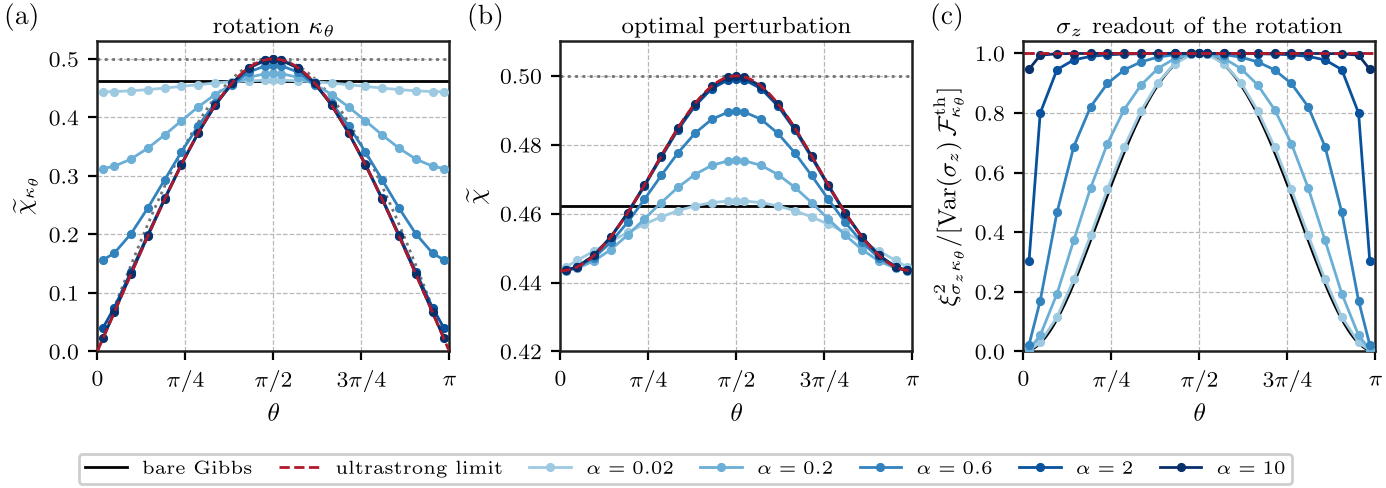

In [4]:
T = read_csv(DATA / 'local_theta.csv')
COUP = {0.01: BLUES[1], 0.1: BLUES[2], 0.3: BLUE_MAIN, 1.0: BLUES[5], 5.0: BLUES[6]}
THETA_TICKS = dict(xlim=(0, np.pi), xticks=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi],
                   xticklabels=['0', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'],
                   xlabel=r'$\theta$')


def mirror(th, y):
    """Extend a curve computed on [0, pi/2] to [0, pi] using the symmetry of the model."""
    th, y = np.asarray(th), np.asarray(y)
    return np.concatenate([th, np.pi - th[::-1][1:]]), np.concatenate([y, y[::-1][1:]])


fig, ax = figure('row3', legend_rows=1)
thf = np.linspace(1e-3, np.pi - 1e-3, 400)
for key, a_ in (('chi_rot', ax[0]), ('chi_opt', ax[1]), ('frac_sz_rot', ax[2])):
    if key == 'chi_rot':
        weak = np.full_like(thf, np.tanh(xq) / (2 * xq))
        usc = 0.5 * np.abs(np.sin(thf)) / np.cosh(xq * np.cos(thf))
        a_.plot(thf, 0.5 * np.abs(np.sin(thf)), color=GREY_REF, ls=':', lw=LW_REF)
    elif key == 'chi_opt':
        weak = np.full_like(thf, np.tanh(xq) / (2 * xq))
        usc = 0.5 / np.cosh(xq * np.cos(thf))
    else:
        weak = np.sin(thf) ** 2 / (1 - np.tanh(xq) ** 2 * np.cos(thf) ** 2)
        usc = np.ones_like(thf)
    a_.plot(thf, weak, color='k', lw=LWD_SB, zorder=2)
    for a in sorted(COUP):
        rr = sort_by(select(T, kind='tempo', alpha=a), 'theta')
        a_.plot(*mirror(*column(rr, 'theta', key)), '-o', color=COUP[a], ms=MS_SB, lw=LWD_SB, zorder=3)
    a_.plot(thf, usc, color=RED, lw=LWD_SB, ls='--', zorder=5)
    a_.axhline(0.5 if key != 'frac_sz_rot' else 1.0, color=GREY_REF, lw=LW_REF, ls=':', zorder=1)
    a_.set(**THETA_TICKS); grid(a_)

ax[0].set(ylim=(0, .53), ylabel=r'$\widetilde\chi_{\kappa_\theta}$')
ax[1].set(ylim=(.42, .51), ylabel=r'$\widetilde\chi$')
ax[2].set(ylim=(0, 1.04),
          ylabel=r'$\xi_{\sigma_z\kappa_\theta}^2/[\mathrm{Var}(\sigma_z)\,\mathcal{F}^{\rm th}_{\kappa_\theta}]$')
title(ax[0], '(a)', r'rotation $\kappa_\theta$')
title(ax[1], '(b)', 'optimal perturbation')
title(ax[2], '(c)', r'$\sigma_z$ readout of the rotation')
h = [Line2D([], [], color='k', lw=LWD_SB, label='bare Gibbs'),
     Line2D([], [], color=RED, lw=LWD_SB, ls='--', label='ultrastrong limit')]
h += [Line2D([], [], color=COUP[a], marker='o', ms=MS_SB, lw=LWD_SB, label=fr'$\alpha={2 * a:g}$')
      for a in sorted(COUP)]
shared_legend(fig, h, ncol=7)
save(fig, 'spin_boson_equilibrium');

Three things happen as the coupling is turned on, and all three are visible in the panels.

**The coupling selects the in-plane rotation (a).** At $\alpha=0$ the transverse channel is
degenerate: $\kappa_\theta$ and $\sigma_y/2$ give the same value, so the black line is flat in
$\theta$. Any $\alpha>0$ lifts the degeneracy in favour of the perturbation along the coupling
axis. The rotation therefore *loses* near alignment, where $\bm n_\theta$ is nearly
perpendicular to $\hat z$, by the factor $|\sin\theta|$ of the ultrastrong limit, and *gains*
around $\theta=\pi/2$, where the rotation is itself a bias.

**The optimum migrates to the bias (b).** The optimal direction $\bm n^*$, the leading
eigenvector of $K$, swings onto the coupling axis as soon as the bath is on, and the bound rises
towards the Curie ceiling $1/2$. Note the scale: panel (b) spans 0.42 to 0.51, so at
$\beta\Delta=1$ the optimal bound is Planckian at *every* coupling. What the coupling changes is
which perturbation attains it, not the order of magnitude.

In [5]:
# local.csv has the three angles of Sec. V on the full coupling grid
print('           theta = pi/2        theta = 1           theta = 0.4')
print(' alpha_L   chi_opt  n*^z   chi_opt  n*^z     chi_opt  n*^z   [n*^z = angle(n*, z) in degrees]')
for a in (0.001, 0.01, 0.1, 0.5, 2.0, 5.0):
    cells = []
    for th in (np.pi / 2, 1.0, 0.4):
        rr = select(L, kind='tempo', alpha=a, theta=th)
        cells.append(f"{rr[0]['chi_opt']:.5f} {rr[0]['nstar_angle_z']:5.1f}" if rr else ' ' * 13)
    print(f'{2 * a:8g}   ' + '   '.join(cells))
print('\nAt theta = pi/2 the rotation is itself the bias, so n* is on the coupling axis at every'
      '\ncoupling. Away from it, n* starts tilted and is pulled onto that axis as alpha grows.')

           theta = pi/2        theta = 1           theta = 0.4
 alpha_L   chi_opt  n*^z   chi_opt  n*^z     chi_opt  n*^z   [n*^z = angle(n*, z) in degrees]
   0.002   0.46228   0.0   0.46173  30.2   0.46058  64.9
    0.02   0.46373   0.0   0.46030  16.6   0.45104  34.4
     0.2   0.47555   0.0   0.46626   2.8   0.44836   2.5
       1   0.49555   0.0   0.47935   0.4   0.45074   0.3
       4   0.49988   0.0   0.48222   0.0   0.45128   0.0
      10   0.49999   0.0   0.48228   0.0   0.45129   0.0

At theta = pi/2 the rotation is itself the bias, so n* is on the coupling axis at every
coupling. Away from it, n* starts tilted and is pulled onto that axis as alpha grows.


**The readout moves to the pointer populations (c).** At weak coupling the SLD of the rotation
is a coherence in the eigenbasis of $H_S$, so measuring $\sigma_z$ recovers only part of the
information — 19% at $\theta=0.4$. At strong coupling the MFG state is diagonal in the pointer
basis, the optimal observable *is* $\sigma_z$, and the fraction goes to 1. This is the same
statement as the migration of $\bm n^*$, seen from the measurement side.

### Low temperature at the symmetric point

At $\theta=\pi/2$ the rotation *is* a bias, $\kappa_{\pi/2}=-\frac12\sigma_z$, and $H_{\rm tot}$
is invariant under a $\pi$ rotation of the spin about $\hat x$ combined with the bath parity
$b_k\to-b_k$. That symmetry flips $\sigma_z$, so $\langle\sigma_z\rangle_{\tilde\omega}=0$ and
$\bm b$ points along $\hat x$: $\bm b$ is an eigenvector of $J$, Eq. (25) applies at every
coupling, and the bound reduces to one isothermal susceptibility [Eq. (39)],

$$\tau\geq\frac{\hbar}{2}\xi_{\sigma_z\sigma_z}
  =-\hbar\,\frac{\partial\langle\sigma_z\rangle_{\tilde\omega}}{\partial h_z}\Big|_{h_z=0}.$$

Since $\mathrm{Var}_{\tilde\omega}(\sigma_z)=1$, Eq. (17) gives $\xi_{\sigma_z\sigma_z}\leq\beta$,
so this can approach but never reach the ceiling $\tau_{\rm Pl}/2$. `local_lowT.csv` evaluates
it at $\beta\Delta=4$, where the weak-coupling value $\tanh(\beta\Delta/2)/(\beta\Delta)$ is
well below the ceiling and the rise with coupling is correspondingly larger.

In [6]:
LT = read_csv(DATA / 'local_lowT.csv')
weak4 = np.tanh(4 / 2) / 4
print(f'beta*Delta = 4, theta = pi/2;  weak-coupling value tanh(2)/4 = {weak4:.5f},  ceiling 1/2')
for r in sort_by(LT, 'alpha'):
    k = [c for c in r if 'chi' in c and r[c] is not None][0]
    print(f'  alpha_L = {2 * r["alpha"]:6g}:  chi_zz/beta = {r[k]:.5f}   '
          f'({r[k] / weak4:.2f} x the weak-coupling value)')

beta*Delta = 4, theta = pi/2;  weak-coupling value tanh(2)/4 = 0.24101,  ceiling 1/2
  alpha_L =  0.002:  chi_zz/beta = 0.24194   (1.00 x the weak-coupling value)
  alpha_L =   0.06:  chi_zz/beta = 0.26937   (1.12 x the weak-coupling value)
  alpha_L =    0.2:  chi_zz/beta = 0.33539   (1.39 x the weak-coupling value)
  alpha_L =    0.6:  chi_zz/beta = 0.45715   (1.90 x the weak-coupling value)
  alpha_L =      2:  chi_zz/beta = 0.49917   (2.07 x the weak-coupling value)
  alpha_L =     10:  chi_zz/beta = 0.49997   (2.07 x the weak-coupling value)


## 4. Thermalization times at finite accuracy (Fig. 4)

Fixing $\theta=\pi/2$ and extending the bias direction as in Eq. (30), with
$\hat\kappa=\sigma_z/2$ and $x=h_z$, gives a one-parameter family on which both sides of the
inequality can be evaluated,

$$H_S(x)=\frac{\Delta}{2}\sigma_x+\frac{x}{2}\sigma_z,\qquad |\beta x|\leq\delta=2\pi,
  \qquad \rho_S(0)=\mathbb I/2 ,$$

with the same ball and accuracies as the fermionic models.

**The bound** (`finite_bound.csv`) needs only the MFG targets: 41 members $x\in[0,2\pi]$ from
imaginary-time TEMPO with Richardson extrapolation $N=100\to200$, a spline in $x$, and a pair
optimization (grid followed by Nelder–Mead). Negative $x$ follows by symmetry.

**The time** (`dynamics.csv`) needs the real-time dynamics, which is the expensive part. Plain
TEMPO costs about 0.6 s per step at the SVD precision needed here, and $\tau_\varepsilon$ can be
$10^5$ steps away, so the pipeline instead computes the exact maps up to $t=K\,dt$ with
untruncated memory ($dt=0.05$, three runs per member) and propagates them with transfer tensors
($K=200$). Inside the window the maps are the full-memory maps; beyond it the transfer tensors
extrapolate, and the extrapolation error is controlled by comparing $K$ with $K/2$ and by the
residual mismatch $\eta$ between the real-time steady state and the imaginary-time MFG state.

That mismatch is what limits the figure. `ss_err_max` is $\eta$; rows with
$\eta\geq0.05$ are dropped, and the remaining points are drawn as filled markers only when
$\eta<0.15\,\varepsilon_{\min}$ *and* the bracket $[\tau(\varepsilon+\eta),\tau(\varepsilon-\eta)]$
is narrower than 3% of $\tau$. Everything else is an open marker with that bracket as its error
bar. This is a numerical limitation of the real-time side only; the bound is unaffected.

In [7]:
B = read_csv(DATA / 'finite_bound.csv')
Dyn = read_csv(DATA / 'dynamics.csv')
fcfg = json.loads((DATA / 'finite_config.json').read_text())
print('bound parameters:', {k: fcfg[k] for k in ('wc', 'beta', 'Delta', 'N', 'delta', 'nx')})

kept = [r for r in Dyn if r['ss_err_max'] < 0.05]
print(f'\ndynamics rows: {len(Dyn)} computed, {len(kept)} with eta < 0.05 '
      f'(alpha_L up to {2 * max(r["alpha"] for r in kept):g} out of {2 * max(r["alpha"] for r in Dyn):g})')

# the theorem, on every row where both sides exist
chk = 0
for r in kept:
    b = select(B, alpha=r['alpha'], eps_fraction=r['eps_fraction'])
    if b and np.isfinite(r['tau']):
        assert r['tau'] >= b[0]['chi'] - 1e-9, r
        chk += 1
print(f'tau_eps >= tau_Pl chi_delta verified on {chk} rows, 0 violations')
print(f'tau_QFI <= tau_eps on all rows: '
      f'{all(r["tau_qfi"] <= r["tau"] + 1e-9 for r in kept if np.isfinite(r["tau"]))}')

bound parameters: {'wc': 10.0, 'beta': 1.0, 'Delta': 1.0, 'N': [100, 200], 'delta': 6.283185307179586, 'nx': 41}

dynamics rows: 50 computed, 45 with eta < 0.05 (alpha_L up to 1.4 out of 2)
tau_eps >= tau_Pl chi_delta verified on 44 rows, 0 violations
tau_QFI <= tau_eps on all rows: True


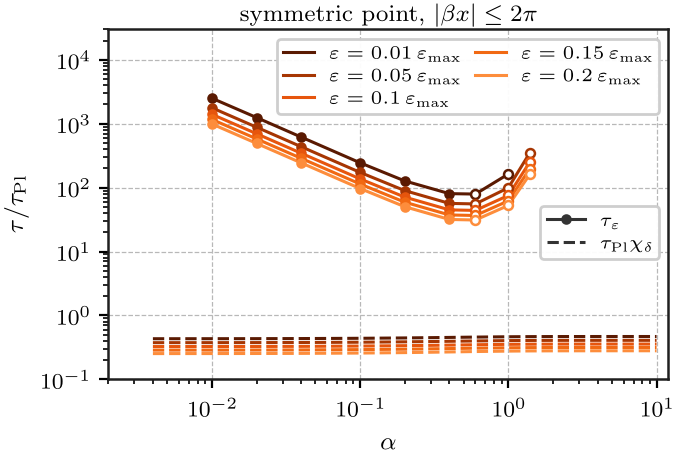

In [8]:
D = kept
eps_min = min(r['eps'] for r in D)
fig, (ax,) = figure('col')
for e, c in EPS_COLOR.items():
    rr = sort_by(select(B, eps_fraction=e), 'alpha')
    ax.plot(*column(rr, 'alpha_L', 'chi'), color=c, lw=LWD, ls='--')

    dd = [r for r in sort_by(select(D, eps_fraction=e), 'alpha') if np.isfinite(r['tau'])]
    x = 2 * column(dd, 'alpha')                      # alpha_L = 2 alpha
    y = column(dd, 'tau')
    good = np.array([(r['ss_err_max'] < 0.15 * eps_min) and np.isfinite(r['tau_hi'])
                     and (r['tau_hi'] - r['tau_lo']) / (2 * r['tau']) < 0.03 for r in dd])
    ax.plot(x, y, color=c, lw=LWD, zorder=3)
    ax.plot(x[good], y[good], 'o', color=c, ms=MS_D, zorder=4)
    if (~good).any():
        lo, hi = column(dd, 'tau_lo', 'tau_hi')
        yerr = np.vstack([y - lo, np.where(np.isfinite(hi), hi - y, 0)])[:, ~good]
        ax.errorbar(x[~good], y[~good], yerr=yerr, fmt='o', mfc='white', mec=c, ecolor=c, mew=0.9,
                    ms=MS_D + 0.4, elinewidth=0.9, zorder=5)

ax.set(xscale='log', yscale='log', xlabel=r'$\alpha$', ylabel=r'$\tau/\tau_{\rm Pl}$',
       xlim=(2e-3, 12), ylim=(0.1, 3e4))
grid(ax)
title(ax, None, r'symmetric point, $|\beta x|\leq2\pi$')
l1 = ax.legend(handles=[Line2D([], [], color=c, lw=LWD, label=eps_label(e)) for e, c in EPS_COLOR.items()],
               loc='upper right', ncol=2, columnspacing=0.8, **ps.LEG)
ax.add_artist(l1)
ax.legend(handles=[Line2D([], [], color='0.2', lw=LWD, marker='o', ms=MS_D, label=r'$\tau_\varepsilon$'),
                   Line2D([], [], color='0.2', lw=LWD, ls='--', label=r'$\tau_{\rm Pl}\chi_\delta$')],
          loc='center right', bbox_to_anchor=(1.0, 0.42), **{**ps.LEG, 'handlelength': 2.0})
save(fig, 'spin_boson_finite_error');

The two sides behave very differently. $\tau_\varepsilon$ falls by three orders of magnitude as
the coupling grows and then turns around near $\alpha_L\approx0.6$, where the dynamics crosses
over to incoherent pointer-basis relaxation. The bound, in contrast, *increases* monotonically
with the coupling at every accuracy, from the bare-Gibbs value to a pinned value which the
weak-coupling resonant-level task of the fermionic notebook reproduces independently:

In [9]:
print('chi_delta of the bias family, by accuracy and coupling:\n')
print(' eps/eps_max   alpha_L=0.004   alpha_L=0.1   alpha_L=1   alpha_L=10')
for e in (0.01, 0.05, 0.1, 0.15, 0.2):
    row = [f'{e:9g}   ']
    for aL in (0.004, 0.1, 1.0, 10.0):
        r = select(B, eps_fraction=e, alpha_L=aL)
        row.append(f'{r[0]["chi"]:.5f}' if r else '  --   ')
    print('       '.join(row))
print('\nThe weakest coupling computed, alpha_L = 0.004, is already within 3e-4 of the bare-Gibbs'
      '\nlimit, and alpha_L = 10 within 1.4e-5 of the pinned strong-coupling value; both limits are'
      '\nverified against independent calculations in check_finite_limits.py (Sec. 5).')

chi_delta of the bias family, by accuracy and coupling:

 eps/eps_max   alpha_L=0.004   alpha_L=0.1   alpha_L=1   alpha_L=10
     0.01          0.43171       0.43849       0.46344       0.46773
     0.05          0.37452       0.38073       0.40370       0.40770
      0.1          0.32569       0.33141       0.35269       0.35645
     0.15          0.28643       0.29174       0.31165       0.31522
      0.2          0.25272       0.25768       0.27641       0.27982

The weakest coupling computed, alpha_L = 0.004, is already within 3e-4 of the bare-Gibbs
limit, and alpha_L = 10 within 1.4e-5 of the pinned strong-coupling value; both limits are
verified against independent calculations in check_finite_limits.py (Sec. 5).


### Why the bound hardly moves

The paper gives the reason exactly. The optimal pair is symmetric, $(-x^*,x^*)$, and the
symmetry of the symmetric point gives its two targets the same coherence $b_x$ and opposite
pointer polarizations $\pm b_z$. Their Bures angle is then

$$D(\tilde\omega_{-x^*},\tilde\omega_{x^*})=\arcsin|b_z| ,$$

so the coherence — the part the coupling destroys — drops out entirely, and for
$k_BT\gtrsim\Delta$ the pointer polarization of the biased members changes little between the
bare and the pinched state. `finite_states.csv` stores $\bm b$ for every member, so both
statements can be checked directly.

In [10]:
St = read_csv(DATA / 'finite_states.csv')
print(' alpha_L     x*      b_x(x*)    b_z(x*)   D(pair)    arcsin|b_z|   chi rebuilt   chi stored')
for aL in (0.004, 0.04, 0.2, 2.0, 10.0):
    b = select(B, alpha_L=aL, eps_fraction=0.05)
    if not b:
        continue
    b = b[0]; xstar = abs(b['x1'])
    rr = sort_by(select(St, alpha=b['alpha']), 'x')
    x, bx, bz = column(rr, 'x', 'bx', 'bz')
    bxs, bzs = np.interp(xstar, x, bx), np.interp(xstar, x, bz)
    D = pk.bures_angle_qubit([bxs, 0, bzs], [bxs, 0, -bzs])
    print(f'{aL:7g}   {xstar:.4f}  {bxs:+.5f}  {bzs:+.5f}   {D:.6f}    {np.arcsin(abs(bzs)):.6f}'
          f'      {pk.chi_pair(D, 2 * xstar, b["eps"]):.5f}       {b["chi"]:.5f}')
print('\nD(pair) and arcsin|b_z| agree to machine precision: the coherence b_x does not enter.'
      '\nThe rebuilt chi is slightly below the stored one because it interpolates the 41-point x'
      '\ngrid linearly, whereas the pipeline splines in x and refines the pair by Nelder-Mead.')

 alpha_L     x*      b_x(x*)    b_z(x*)   D(pair)    arcsin|b_z|   chi rebuilt   chi stored
  0.004   1.3872  -0.40266  -0.56276   0.597722    0.597722      0.37426       0.37452
   0.04   1.3816  -0.37745  -0.56380   0.598983    0.598983      0.37669       0.37699
    0.2   1.3621  -0.28420  -0.56772   0.603729    0.603729      0.38557       0.38600
      2   1.3224  -0.03340  -0.57780   0.616028    0.616028      0.40645       0.40699
     10   1.3215  -0.00528  -0.57827   0.616601    0.616601      0.40717       0.40770

D(pair) and arcsin|b_z| agree to machine precision: the coherence b_x does not enter.
The rebuilt chi is slightly below the stored one because it interpolates the 41-point x
grid linearly, whereas the pipeline splines in x and refines the pair by Nelder-Mead.


### Speed limits offer no comparison here

Unlike in the fermionic models, the Shiraishi–Saito bound cannot be evaluated for this task.
Its trajectory form needs the energy fluctuations of $H_S+V$ in the state of the *compound*,
which methods for the reduced dynamics do not provide, and it needs the reduced trajectory up
to $\tau_\varepsilon$ — hence $\tau_\varepsilon$ itself. Its static form,
$2\hbar\mathcal D/\|H_S+V\|$, vanishes identically because $\|V\|$ is unbounded for a bosonic
bath. This is the lack of robustness that Sec. II D describes, in its sharpest form.

The repository nevertheless still carries `src/spin_boson/ss_bound.py` and
`data/spin_boson/ss_upper.csv`, which evaluate a dynamics-free *upper* bound on $\tau_{\rm SS}$
derived during this work (a variational lower bound on $\delta E_S$ that needs only the MFG
targets and the spectral density). It was used to confirm that no evaluation of the
Shiraishi–Saito bound could exceed ours here; the final manuscript makes the point without it,
so it is shipped as supporting material rather than as a result of the paper. Its derivation
is checked step by step against exact diagonalization in `check_ss_bound.py`.

## 5. Numerical method and its validation

The MFG states come from OQuPy 0.5.0 (`GibbsTempo`, imaginary time) with three corrections, all
in `src/spin_boson/sb_core.py`:

1. **Imaginary-time bath coefficients.** An overflow guard in the released code drops a term
   that is $O(1)$ as $\tau\to\beta$, which biases the coefficients coupling the first and last
   slices; the bias does not decrease with the number of slices. `MatsubaraSD` replaces them by
   a stable quadrature of the twice-integrated kernel. After the fix the reference value of
   Chiu *et al.* is reproduced more closely than by the released code.
2. **Transposition.** `GibbsTempo` returns $\tilde\rho^{\mathsf T}$, which is invisible for a
   real Bloch vector but flips the sign of $\langle\sigma_y\rangle$; `mfg_state()` transposes back.
3. **Real-time $\eta(t)$** is replaced by its closed form for this spectral density, which also
   serves as a check on the quadrature of the released code (they agree to $2\times10^{-8}$).

Fourteen independent check scripts accompany the pipeline. Each tests one claim against an
independent calculation and, where possible, against deliberately mutated versions of itself
that it must reject — a brute-force path sum against the imaginary-time machinery, the closed
form of $\eta$ against its defining double integral, the response identities
$J_{yy}=b_x/h_x$ and $J_{xz}=J_{zx}$, the steps of the $\delta E_S$ lemma against exact
diagonalization of a qubit plus two modes, the weak-coupling limit of the finite-error family
against the resonant-level task of the fermionic notebook, and the Theorem itself on every row.
Their output is in `src/spin_boson/logs/`.

In [11]:
for name in ('local_results', 'finite_limits', 'gibbs_pathsum', 'ss_bound', 'local_symmetry'):
    txt = (Path('src/spin_boson/logs') / f'logs_check_{name}.txt').read_text().strip().split('\n')
    print(f'--- check_{name}.py ---')
    print('\n'.join(txt[-3:]), '\n')

--- check_local_results.py ---
theta=1.0000: (i) 0.46173 vs weak 0.46212 [True]  (ii) 0.48228/0.48229, rot 0.40584/0.40584 [True]  (iii) max asym 2.5e-05 [True]  (iv) rich 1.0e-04, stencil 5.2e-05 [True]  (v) max chi 0.48228 [True]  (vi) [True]
theta=0.4000: (i) 0.46058 vs weak 0.46212 [True]  (ii) 0.45129/0.45129, rot 0.17581/0.17574 [True]  (iii) max asym 4.7e-06 [True]  (iv) rich 1.0e-04, stencil 4.9e-05 [True]  (v) max chi 0.46058 [True]  (vi) [True]
RESULT: PASS 

--- check_finite_limits.py ---
   TEMPO eps=0.15: chi(alpha=0.002)=0.28643 vs bare 0.28618 (diff +2.4e-04);  chi(alpha=5)=0.31522 vs pinned 0.31523 (diff -1.3e-05)
   TEMPO eps=0.20: chi(alpha=0.002)=0.25272 vs bare 0.25249 (diff +2.3e-04);  chi(alpha=5)=0.27982 vs pinned 0.27983 (diff -1.3e-05)
RESULT: PASS 

--- check_gibbs_pathsum.py ---
failure control 'sym_transposed': max deviation 6.92e-02 -> rejected (good)
failure control 'raw_oqupy': max deviation 6.93e-02 -> rejected (good)
RESULT: PASS 

--- check_ss_bound.py

One check does not pass everywhere, and that is reported rather than hidden.
`check_dynamics.py` applies five gates to each of the 50 real-time rows: (i) the Theorem,
(ii) the real-vs-imaginary steady-state mismatch $\eta<0.15\,\varepsilon_{\min}$ with a bracket
below 3%, (iii) transfer-tensor memory, $|\tau(K)-\tau(K/2)|/\tau<5\%$, (iv) sustained
thermalization, and (v) the speed-limit chain $\tau_{\rm QFI}\leq\tau_\varepsilon$. Thirty rows
clear all five, and they are exactly the couplings $\alpha_L\leq0.4$. Fourteen rows,
$\alpha_L=0.6$ to $1.4$, fail gate (ii) alone — the mismatch that the open markers in Fig. 4
encode. The remaining six, at $\alpha_L=2$, have no $\tau_\varepsilon$ within the horizon at all
and fail (i), (ii), (iii) and (v) for that reason; they are the rows the figure drops. The
number on the final line of the log counts failed gate *instances*, $14\times1+6\times4=38$,
not rows.

In [12]:
txt = (Path('src/spin_boson/logs') / 'logs_check_dynamics.txt').read_text().strip().split('\n')
print('\n'.join(txt[-6:]))

alpha=1      eps=0.01  tau=      nan chi=0.4670 tau_K2=      nan tau_QFI=     nan ss_err=2.1e-01 last_exit=   nan  FAIL i,ii,iii,v
alpha=1      eps=0.05  tau=      nan chi=0.4070 tau_K2=      nan tau_QFI=     nan ss_err=2.1e-01 last_exit=   nan  FAIL i,ii,iii,v
alpha=1      eps=0.1   tau=      nan chi=0.3558 tau_K2=      nan tau_QFI=     nan ss_err=2.1e-01 last_exit=   nan  FAIL i,ii,iii,v
alpha=1      eps=0.15  tau=      nan chi=0.3146 tau_K2=      nan tau_QFI=     nan ss_err=2.1e-01 last_exit=   nan  FAIL i,ii,iii,v
alpha=1      eps=0.2   tau=      nan chi=0.2792 tau_K2=      nan tau_QFI=     nan ss_err=2.1e-01 last_exit=   nan  FAIL i,ii,iii,v
RESULT: FAIL (38)


## 6. Recomputing the data

The scripts live in `src/spin_boson/` and write into `data/spin_boson/`. They need OQuPy 0.5.0,
which pins NumPy < 2 and is therefore **not** in this repository's `requirements.txt`; use a
separate environment:

```
python3.11 -m venv venv_tempo && venv_tempo/bin/pip install oqupy==0.5.0
venv_tempo/bin/python src/spin_boson/compute_local_theta.py
```

| script | output | cost |
|---|---|---|
| `compute_local.py` | `local.csv` | ~860 MFG states |
| `compute_local_theta.py` | `local_theta.csv` (Fig. 3) | ~60 MFG states |
| `compute_local_lowT.py` | `local_lowT.csv` | 24 states, $N=400\to800$ |
| `compute_finite_bound.py` | `finite_bound.csv`, `finite_states.csv` | ~1150 states |
| `precompute_maps.py` | `data/spin_boson/maps/` (not distributed) | 3–15 CPU-min per member |
| `compute_dynamics.py` | `dynamics.csv` (Fig. 4) | seconds, once the maps exist |
| `compute_ss_upper.py` | `ss_upper.csv` | quadratures |
| `check_*.py` | `logs/` | each exits non-zero on failure |

The real-time maps and the MFG cache are intermediates and are not shipped: `precompute_maps.py`
regenerates them, and every script that needs them creates `data/spin_boson/maps/` on first run.
Everything the figures and the tables of the paper use is in the CSV files above.